In [388]:
import pandas as pd
import scipy
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [389]:
import pandas as pd

df = pd.read_excel("Flipkart_Sales_Analysis_Corrected(2)_2.xlsx")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (19, 8)


,Flipkart E-Commerce Sales Analysis,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,"Excel analysis workbook | Dataset: 1,000 recor...",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,KEY PERFORMANCE INDICATORS,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Total Sales,75213112.74,Total Profit,1.504262e+07,Profit Margin,0.2,Units Sold,3097.0
4,All records combined,NaN,Sum of recorded profit,NaN,Profit ÷ sales,NaN,Sum of quantity_sold,NaN


In [390]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (19, 8)

Column names:
['Flipkart E-Commerce Sales Analysis', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']


In [391]:
excel = pd.ExcelFile("Flipkart_Sales_Analysis_Corrected(2)_2.xlsx")
print(excel.sheet_names)




['Executive Summary', 'Category Analysis', 'Monthly Trends', 'Data Quality', 'flipkart_sales_cleaned']


In [392]:
df = pd.read_excel(
    "Flipkart_Sales_Analysis_Corrected(2)_2.xlsx",
    sheet_name="flipkart_sales_cleaned"
)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (1000, 26)

Column names:
['order_id', 'product_name', 'category', 'price_inr', 'quantity_sold', 'total_sales_inr', 'order_date', 'payment_method', 'customer_rating', 'month', 'year', 'profit_inr', 'discount_percent', 'customer_segment', 'region', 'calculated_sales', 'sales_difference', 'profit_margin_percent', 'revenue_per_unit', 'profit_per_unit', 'month_number', 'quarter', 'year_month', 'discount_amount', 'net_sales_after_discount', 'month_start']


,order_id,product_name,category,price_inr,quantity_sold,total_sales_inr,order_date,payment_method,customer_rating,month,...,sales_difference,profit_margin_percent,revenue_per_unit,profit_per_unit,month_number,quarter,year_month,discount_amount,net_sales_after_discount,month_start
0,ORD00012,Lipstick,Beauty,48780.78,5,243903.90,2024-04-13,UPI,1.3,April,...,0,0.2,48780.78,9756.156,4,Q2,2024-04-01,36585.5850,207318.32,2024-04-01
1,ORD00684,Dress,Clothing,48130.60,5,240653.00,2024-11-23,UPI,4.0,November,...,0,0.2,48130.60,9626.120,11,Q4,2024-11-01,26471.8300,214181.17,2024-11-01
2,ORD00588,Jeans,Clothing,47535.79,5,237678.95,2024-02-15,Debit Card,1.8,February,...,0,0.2,47535.79,9507.158,2,Q1,2024-02-01,71303.6850,166375.27,2024-02-01
3,ORD00925,Jeans,Clothing,47480.71,5,237403.55,2024-09-09,UPI,3.1,September,...,0,0.2,47480.71,9496.142,9,Q3,2024-09-01,35610.5325,201793.02,2024-09-01
4,ORD00864,Self-Help Book,Books,47427.30,5,237136.50,2024-03-29,Wallet,4.0,March,...,0,0.2,47427.30,9485.460,3,Q1,2024-03-01,71140.9500,165995.55,2024-03-01


In [393]:
print("Total rows:", len(df))
print("\nMissing values in each column:")
print(df.isnull().sum())

Total rows: 1000

Missing values in each column:
order_id                    0
product_name                0
category                    0
price_inr                   0
quantity_sold               0
total_sales_inr             0
order_date                  0
payment_method              0
customer_rating             0
month                       0
year                        0
profit_inr                  0
discount_percent            0
customer_segment            0
region                      0
calculated_sales            0
sales_difference            0
profit_margin_percent       0
revenue_per_unit            0
profit_per_unit             0
month_number                0
quarter                     0
year_month                  0
discount_amount             0
net_sales_after_discount    0
month_start                 0
dtype: int64


In [394]:
print("TOTAL SALES:", df["total_sales_inr"].sum())
print("TOTAL PROFIT:", df["profit_inr"].sum())
print("AVERAGE CUSTOMER RATING:", df["customer_rating"].mean())
print("TOTAL ORDERS:", df["order_id"].nunique())


TOTAL SALES: 75213112.74
TOTAL PROFIT: 15042622.548
AVERAGE CUSTOMER RATING: 3.0111000000000003
TOTAL ORDERS: 1000


In [395]:
total_sales = df["total_sales_inr"].sum()
total_profit = df["profit_inr"].sum()

profit_margin = (total_profit / total_sales) * 100

print(f"Overall Profit Margin: {profit_margin:.2f}%")

Overall Profit Margin: 20.00%


In [396]:
from scipy import stats

ratings = df["customer_rating"].dropna()

print("Average rating:", round(ratings.mean(), 2))
print("Rating standard deviation:", round(ratings.std(), 2))

result = stats.ttest_1samp(ratings, popmean=3)

print("T-statistic:", round(result.statistic, 3))
print("P-value:", round(result.pvalue, 4))


Average rating: 3.01
Rating standard deviation: 1.15
T-statistic: 0.306
P-value: 0.7593


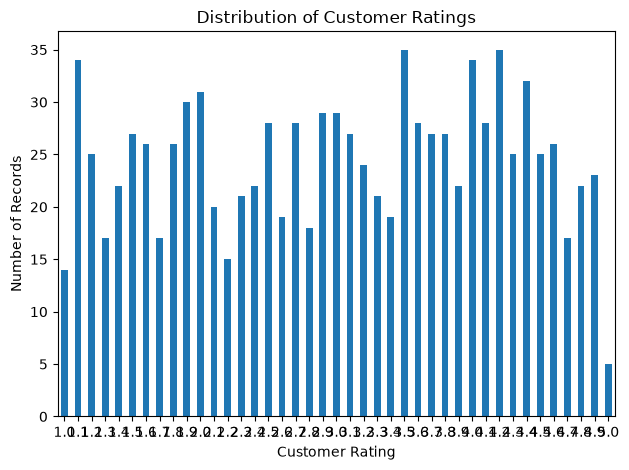

In [397]:
import matplotlib.pyplot as plt

df["customer_rating"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()




category
Electronics       17307173.07
Clothing          15114386.86
Books             14785759.65
Beauty            14680584.05
Home & Kitchen    13325209.11
Name: total_sales_inr, dtype: float64


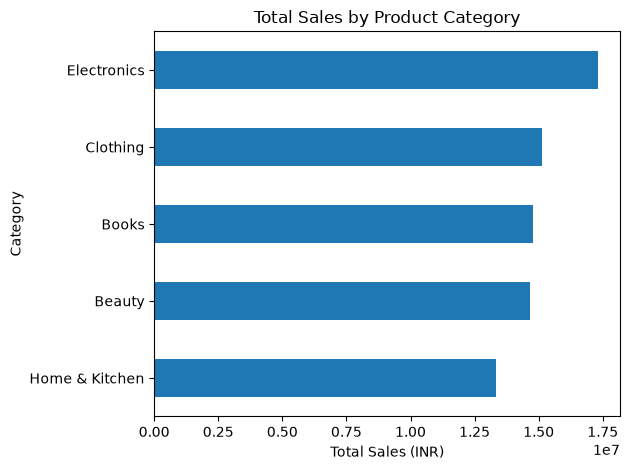

In [398]:
category_sales = df.groupby("category")["total_sales_inr"].sum()

print(category_sales.sort_values(ascending=False))

category_sales.sort_values().plot(kind="barh")

plt.title("Total Sales by Product Category")
plt.xlabel("Total Sales (INR)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


order_date
2024-02    3910477.01
2024-03    6508879.04
2024-04    7334962.92
2024-05    6706004.97
2024-06    4992364.75
2024-07    7637324.95
2024-08    5418893.98
2024-09    6264222.31
2024-10    5702923.37
2024-11    5578535.08
2024-12    6491639.99
2025-01    7160788.17
2025-02    1506096.20
Freq: M, Name: total_sales_inr, dtype: float64


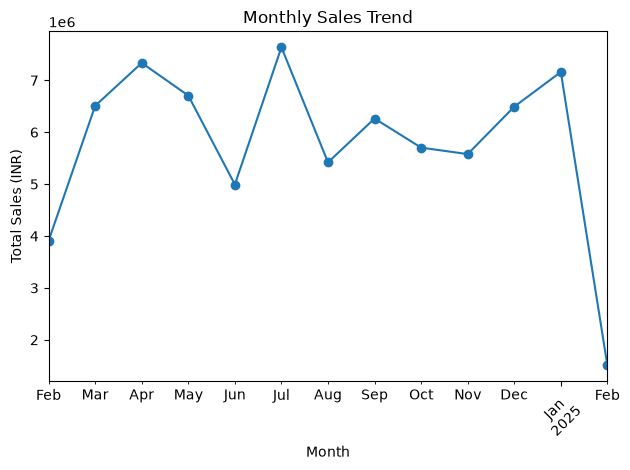

In [399]:
df["order_date"] = pd.to_datetime(df["order_date"])

monthly_sales = df.groupby(
    df["order_date"].dt.to_period("M")
)["total_sales_inr"].sum()

print(monthly_sales)

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [400]:
from scipy.stats import pearsonr

data = df[["discount_percent", "total_sales_inr"]].dropna()

correlation, p_value = pearsonr(
    data["discount_percent"],
    data["total_sales_inr"]
)

print("Correlation:", round(correlation, 3))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("The relationship is statistically significant.")
else:
    print("The relationship is not statistically significant.")
    

Correlation: -0.016
P-value: 0.621
The relationship is not statistically significant.


                mean  count   std
category                         
Home & Kitchen  3.14    193  1.17
Books           3.08    209  1.18
Electronics     2.99    217  1.15
Clothing        2.97    189  1.09
Beauty          2.87    192  1.12


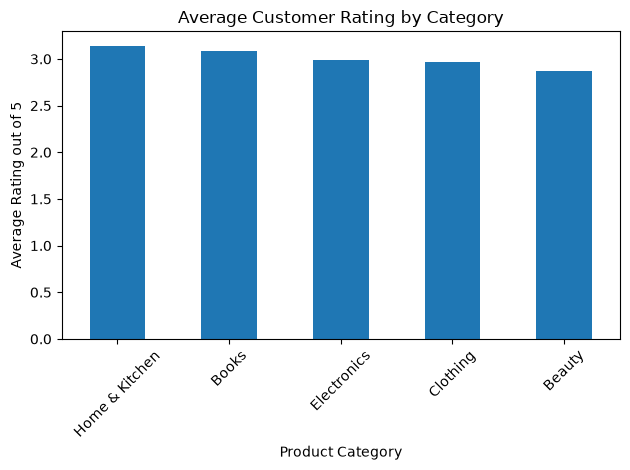

In [401]:
category_ratings = df.groupby("category")["customer_rating"].agg(
    ["mean", "count", "std"]
)

category_ratings = category_ratings.sort_values(
    by="mean", ascending=False
)

print(category_ratings.round(2))

category_ratings["mean"].plot(kind="bar")

plt.title("Average Customer Rating by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Rating out of 5")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [402]:
low_ratings = df[df["customer_rating"] < 3]

print("Records rated below 3:", len(low_ratings))
print("Percentage of records rated below 3:",
      round(len(low_ratings) / len(df) * 100, 2), "%")

print("\nLow-rated records by category:")
print(low_ratings["category"].value_counts())

Records rated below 3: 469
Percentage of records rated below 3: 46.9 %

Low-rated records by category:
category
Electronics       107
Beauty            102
Books              97
Clothing           84
Home & Kitchen     79
Name: count, dtype: int64


                sum  count  low_rating_percent
category                                      
Beauty          102    192               53.12
Electronics     107    217               49.31
Books            97    209               46.41
Clothing         84    189               44.44
Home & Kitchen   79    193               40.93


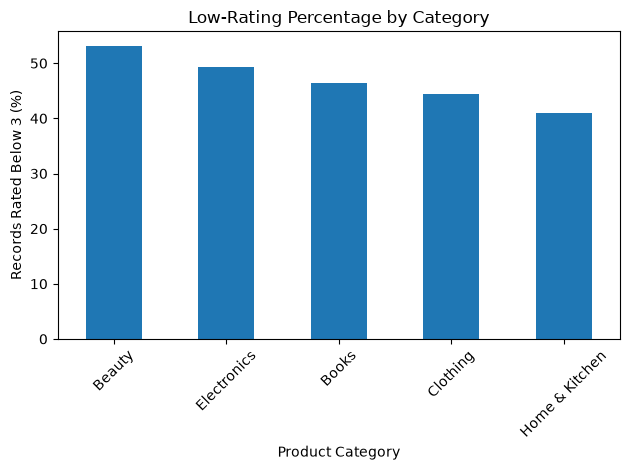

In [403]:
df["low_rating"] = df["customer_rating"] < 3

category_low_rating = (
    df.groupby("category")["low_rating"]
    .agg(["sum", "count", "mean"])
)

category_low_rating["low_rating_percent"] = (
    category_low_rating["mean"] * 100
)

category_low_rating = category_low_rating.sort_values(
    "low_rating_percent", ascending=False
)

print(category_low_rating[["sum", "count", "low_rating_percent"]].round(2))

category_low_rating["low_rating_percent"].plot(kind="bar")

plt.title("Low-Rating Percentage by Category")
plt.xlabel("Product Category")
plt.ylabel("Records Rated Below 3 (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [404]:
from scipy.stats import f_oneway

category_groups = [
    group["customer_rating"].dropna().values
    for _, group in df.groupby("category")
]

f_stat, p_value = f_oneway(*category_groups)

print("ANOVA F-statistic:", round(f_stat, 3))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Average ratings differ significantly across categories.")
else:
    print("No statistically significant difference found across categories.")

ANOVA F-statistic: 1.574
P-value: 0.179
No statistically significant difference found across categories.


In [405]:
with pd.ExcelWriter("Flipkart_Python_Analysis_Results.xlsx") as writer:
    category_ratings.to_excel(
        writer, sheet_name="Category Ratings"
    )
    category_low_rating.to_excel(
        writer, sheet_name="Low Rating Analysis"
    )
    monthly_sales.to_frame(
        name="Total Sales"
    ).to_excel(writer, sheet_name="Monthly Sales")

print("Analysis results exported successfully!")


Analysis results exported successfully!


                total_sales  total_profit  profit_margin_percent
category                                                        
Electronics     17307173.07    3461434.61                   20.0
Clothing        15114386.86    3022877.37                   20.0
Books           14785759.65    2957151.93                   20.0
Beauty          14680584.05    2936116.81                   20.0
Home & Kitchen  13325209.11    2665041.82                   20.0


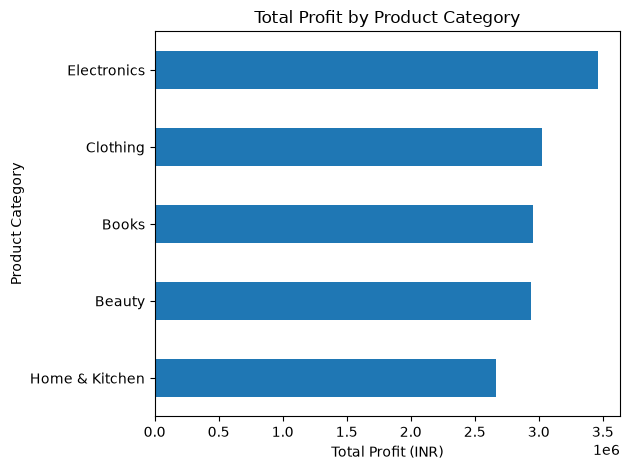

In [406]:
category_profit = df.groupby("category").agg(
    total_sales=("total_sales_inr", "sum"),
    total_profit=("profit_inr", "sum")
)

category_profit["profit_margin_percent"] = (
    category_profit["total_profit"]
    / category_profit["total_sales"] * 100
)

category_profit = category_profit.sort_values(
    "total_profit", ascending=False
)

print(category_profit.round(2))

category_profit["total_profit"].sort_values().plot(
    kind="barh"
)

plt.title("Total Profit by Product Category")
plt.xlabel("Total Profit (INR)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

                total_sales  order_count  average_rating
payment_method                                          
COD             12457136.55          169            2.98
Credit Card     11155785.99          146            3.12
Debit Card      12142559.04          171            3.01
Net Banking     13219947.52          166            2.94
UPI             12790919.48          176            3.07
Wallet          13446764.16          172            2.95


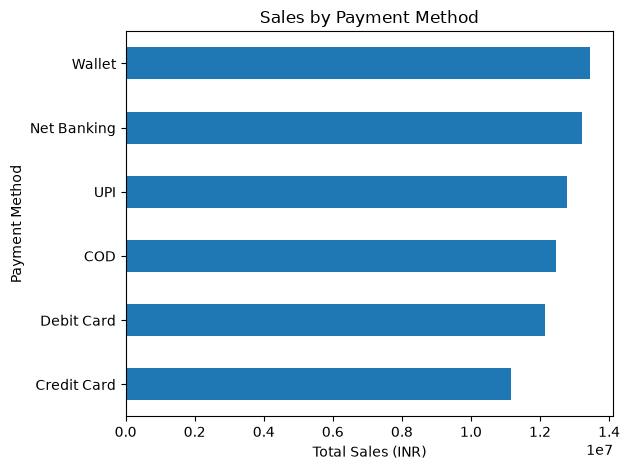

In [407]:
payment_analysis = df.groupby("payment_method").agg(
    total_sales=("total_sales_inr", "sum"),
    order_count=("order_id", "nunique"),
    average_rating=("customer_rating", "mean")
)

print(payment_analysis.round(2))

payment_analysis["total_sales"].sort_values().plot(
    kind="barh"
)

plt.title("Sales by Payment Method")
plt.xlabel("Total Sales (INR)")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

        total_sales  total_profit  order_count  average_rating
region                                                        
North   20289991.87    4057998.37          259            3.08
South   19862508.71    3972501.74          269            2.98
West    18392767.90    3678553.58          246            2.94
East    16667844.26    3333568.85          226            3.05


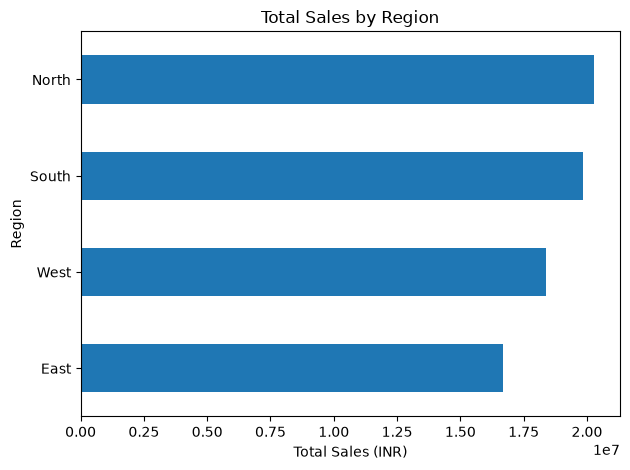

In [408]:
region_analysis = df.groupby("region").agg(
    total_sales=("total_sales_inr", "sum"),
    total_profit=("profit_inr", "sum"),
    order_count=("order_id", "nunique"),
    average_rating=("customer_rating", "mean")
)

region_analysis = region_analysis.sort_values(
    "total_sales", ascending=False
)

print(region_analysis.round(2))

region_analysis["total_sales"].sort_values().plot(
    kind="barh"
)

plt.title("Total Sales by Region")
plt.xlabel("Total Sales (INR)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


                  total_sales  total_profit  order_count  average_rating
customer_segment                                                        
Wholesale         25732035.67    5146407.13          330            2.98
Online            25169884.13    5033976.83          331            3.07
Retail            24311192.94    4862238.59          339            2.98


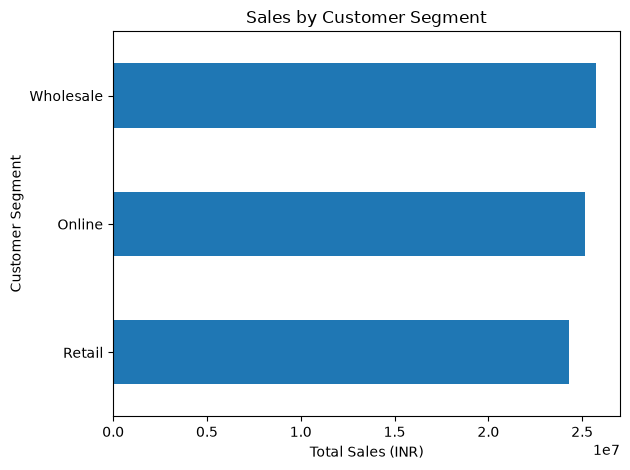

In [409]:
segment_analysis = df.groupby("customer_segment").agg(
    total_sales=("total_sales_inr", "sum"),
    total_profit=("profit_inr", "sum"),
    order_count=("order_id", "nunique"),
    average_rating=("customer_rating", "mean")
)

segment_analysis = segment_analysis.sort_values(
    "total_sales", ascending=False
)

print(segment_analysis.round(2))

segment_analysis["total_sales"].sort_values().plot(
    kind="barh"
)

plt.title("Sales by Customer Segment")
plt.xlabel("Total Sales (INR)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

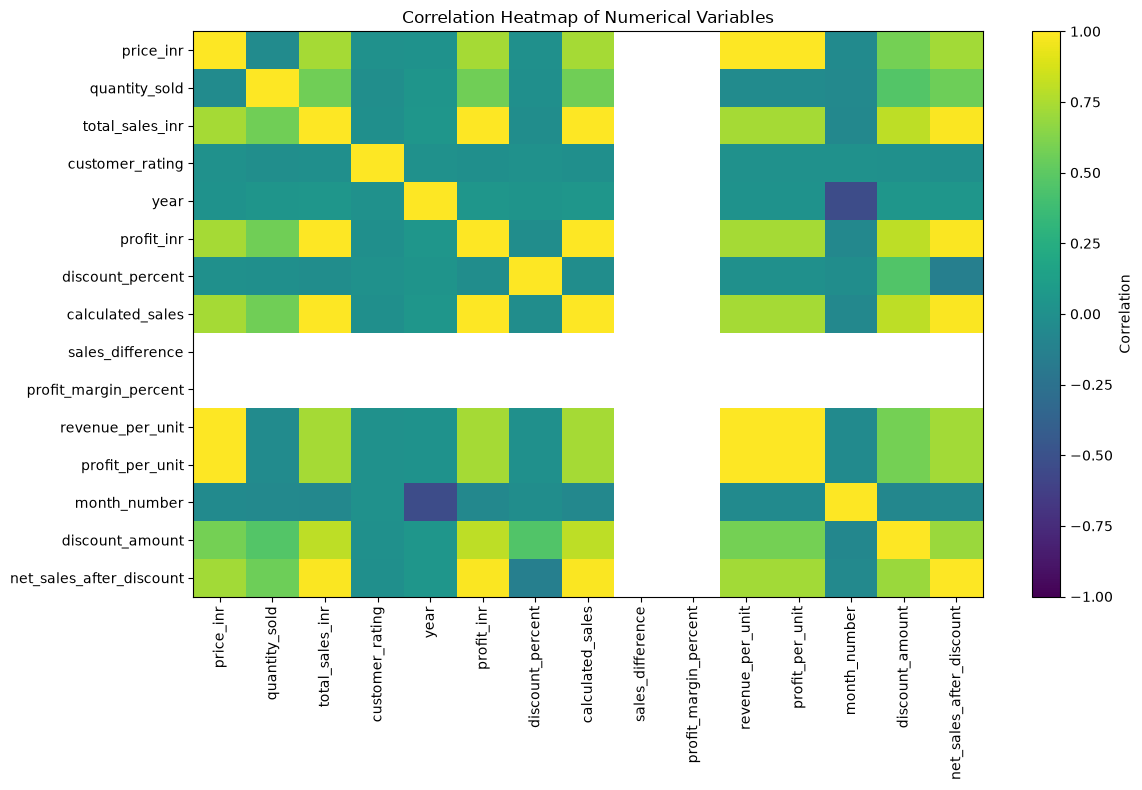

In [410]:
numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))
plt.imshow(correlation_matrix, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

In [411]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Profit Margin (%)",
        "Average Customer Rating",
        "Unique Orders",
        "Records Rated Below 3 (%)",
        "Discount-Sales Correlation",
        "Rating ANOVA P-value"
    ],
    "Value": [
        df["total_sales_inr"].sum(),
        df["profit_inr"].sum(),
        df["profit_inr"].sum() / df["total_sales_inr"].sum() * 100,
        df["customer_rating"].mean(),
        df["order_id"].nunique(),
        (df["customer_rating"] < 3).mean() * 100,
        correlation,
        p_value
    ]
})

print(kpi_summary.round(3).to_string(index=False))

kpi_summary.to_excel("Flipkart_Project_KPI_Summary.xlsx", index=False)

print("\nKPI summary saved successfully!")

                    Metric        Value
               Total Sales 75213112.740
              Total Profit 15042622.548
         Profit Margin (%)       20.000
   Average Customer Rating        3.011
             Unique Orders     1000.000
 Records Rated Below 3 (%)       46.900
Discount-Sales Correlation       -0.016
      Rating ANOVA P-value        0.179

KPI summary saved successfully!


In [412]:
report = f"""
E-COMMERCE CUSTOMER ANALYTICS AND REVIEW OPTIMIZATION
PYTHON ANALYSIS REPORT

1. DATASET
Total records: {len(df)}
Total columns: {len(df.columns)}
Missing values: {int(df.isnull().sum().sum())}

2. BUSINESS PERFORMANCE
Total sales: Rs. {df['total_sales_inr'].sum():,.2f}
Total profit: Rs. {df['profit_inr'].sum():,.2f}
Profit margin: {df['profit_inr'].sum() / df['total_sales_inr'].sum() * 100:.2f}%
Unique order IDs: {df['order_id'].nunique()}
Average customer rating: {df['customer_rating'].mean():.2f}/5

3. CUSTOMER RATINGS
Records rated below 3: {(df['customer_rating'] < 3).sum()}
Percentage rated below 3: {(df['customer_rating'] < 3).mean() * 100:.2f}%

4. STATISTICAL ANALYSIS
Discount-sales correlation: {pearsonr(data['discount_percent'], data['total_sales_inr']).statistic:.3f}
Discount-sales p-value: {pearsonr(data['discount_percent'], data['total_sales_inr']).pvalue:.4f}

5. INTERPRETATION
The dataset's average rating is approximately {df['customer_rating'].mean():.2f}/5.
Low-rated records deserve further investigation.
Correlation does not establish causation.
The findings describe the available dataset and do not prove why
customers gave their ratings.

END OF REPORT
"""

with open("Flipkart_Python_Analysis_Report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("Project report created successfully!")

Project report created successfully!
